# Implementation Roadmap: FreshRoute GTA Pilot

**Where this picks up:** the
[`market-entry-case-toolkit`](https://github.com/rxj0102/market-entry-case-toolkit)
project answered the question *"should FreshRoute enter the Greater Toronto
Area online grocery delivery market?"* with a **conditional go**: the market
opportunity, competitive white space, and operating-model fit all cleared the
bar, but the standalone financial case for a full ~$18M CAD upfront launch
did not clear payback within five years under any modeled scenario. The
recommendation was to proceed anyway, restructured as a **milestone-gated,
partnership-based pilot** in a subset of the GTA — proving out retention,
delivery-cost, and CAC assumptions before committing to full-scale
build-out economics, reassessed at the 18–24 month mark.

That memo is where a market-entry case toolkit's job ends and an
implementation-planning toolkit's job begins. This notebook builds the layer
a real consulting team delivers next: who owns what, who signs off on what,
when the client can still walk away cheaply, what could go wrong operationally
(not commercially — that was the other project's job), how the org gets
communicated with and managed through the change, and how the case team
itself is staffed and mentors its junior members through it.

Every module below is a **plain, testable Python module** in
`src/strategy_roadmap/` — see the README for the full package layout and the
`tests/` directory for the unit tests each module ships with.

In [1]:
import sys
from pathlib import Path

try:
    import strategy_roadmap  # noqa: F401
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

OUTPUTS = Path.cwd().parent / "outputs"
EXHIBITS = OUTPUTS / "exhibits"
EXHIBITS.mkdir(parents=True, exist_ok=True)


## 1. The handoff — where the original case left off

`case_context.py` is the single place this project restates the original
case's facts: the client, the conditional-go recommendation, the pilot scope,
and — most importantly for everything that follows — the three
hypothesis-tree branches the original analysis left only **partially
supported** or **not supported**. These aren't abstract caveats; they're the
specific things the pilot has to prove, and they drive the go/no-go gate
criteria in Section 4 and several rows of the risk register in Section 5.

In [2]:
from strategy_roadmap.case_context import build_case_context

case = build_case_context()
print(f"Client: {case.client_name}")
print(f"Original recommendation: {case.original_recommendation}\n")
print(f"Pilot scope: {case.pilot_scope}\n")
print("Unresolved hypotheses this implementation plan must close:\n")
for h in case.unresolved_hypotheses:
    print(f"[{h.id}] {h.statement}")
    print(f"    Original verdict: {h.original_verdict}")
    print(f"    What the pilot must prove: {h.what_the_pilot_must_prove}\n")


Client: FreshRoute
Original recommendation: Conditional go: proceed via a milestone-gated, partnership-based pilot in a subset of the GTA to prove out retention, delivery-cost, and CAC assumptions, with a formal reassessment of full-scale build-out economics at the 18-24 month mark.

Pilot scope: A single pilot zone within the GTA (a subset of serviceable postal codes, not the full metro), operated via partner-store picking and a third-party last-mile courier network rather than a new owned warehouse -- deliberately capital-light so the pilot can fail cheaply if the unresolved hypotheses don't hold.

Unresolved hypotheses this implementation plan must close:

[3.1] Fulfillment model (partner-store picking + last-mile courier network) is replicable in the GTA without a new warehouse buildout
    Original verdict: partially supported
    What the pilot must prove: Partner-store picking accuracy and last-mile courier delivery cost per order hold within the assumptions used in the financia

## 2. Workstream decomposition

The conditional-go recommendation becomes five discrete, owned,
dependency-sequenced workstreams. Regulatory & Licensing is the critical-path
root — nothing else can safely launch in-market before FreshRoute can legally
operate in Ontario. Marketing Launch is deliberately last: spending
customer-acquisition dollars before the fulfillment model is proven would
burn the exact CAC assumption the pilot exists to test cleanly.

In [3]:
from strategy_roadmap.workstream_planner import (
    build_workstreams,
    compute_waves,
    sequence_workstreams,
    to_markdown as workstreams_to_markdown,
)

workstreams = build_workstreams()
sequenced = sequence_workstreams(workstreams)
waves = compute_waves(workstreams)

for ws in sequenced:
    deps = ", ".join(ws.dependencies) if ws.dependencies else "None"
    print(f"[{ws.id}] {ws.name} (wave {waves[ws.id]}) — owner: {ws.owner_role}")
    print(f"    depends on: {deps}")
    if ws.resolves_hypothesis_id:
        print(f"    resolves case hypothesis: {ws.resolves_hypothesis_id}")


[WS1] Regulatory & Licensing (wave 0) — owner: Regulatory & Compliance Lead (client)
    depends on: None
    resolves case hypothesis: 3.2
[WS2] Fulfillment Infrastructure (wave 1) — owner: Fulfillment Lead (client)
    depends on: WS1
    resolves case hypothesis: 3.1
[WS3] Local Hiring & Talent (wave 1) — owner: HR / Local Operations Lead (client)
    depends on: WS1
    resolves case hypothesis: 3.2
[WS4] Technology Integration (wave 1) — owner: Technology Integration Lead (client)
    depends on: WS1
[WS5] Marketing Launch (wave 2) — owner: Marketing Lead (client)
    depends on: WS2, WS3, WS4
    resolves case hypothesis: 4


## 3. RACI matrix

Ownership isn't enough on its own — a real implementation plan says who else
has to sign off, be consulted, or just stay informed, across *both* the
client organization and the case team's own seniority ladder. Every row has
exactly one Accountable owner (`raci_builder.py` enforces this at
construction time, not just by convention).

## RACI Matrix

| Workstream | Client Sponsor (SVP, International Expansion) | Client CFO | Regulatory & Compliance Lead | Fulfillment Lead | HR / Local Operations Lead | Technology Integration Lead | Marketing Lead | Case Team Partner | Case Team Manager | Case Team Consultant | Case Team Associate Consultant |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Regulatory & Licensing | I | - | A | I | I | I | I | I | C | R | R |
| Fulfillment Infrastructure | I | - | I | A | I | I | I | I | C | R | R |
| Local Hiring & Talent | I | - | I | I | A | I | I | I | C | R | R |
| Technology Integration | I | - | I | I | I | A | I | I | C | R | R |
| Marketing Launch | I | C | I | I | I | I | A | I | C | R | R |
| Program Governance & Go/No-Go Gate Decisions | A | C | I | I | I | I | I | C | R | R | I |

**Legend:** R = Responsible (does the work), A = Accountable (owns the outcome, exactly one per row), C = Consulted (two-way input before a decision), I = Informed (one-way notification afte

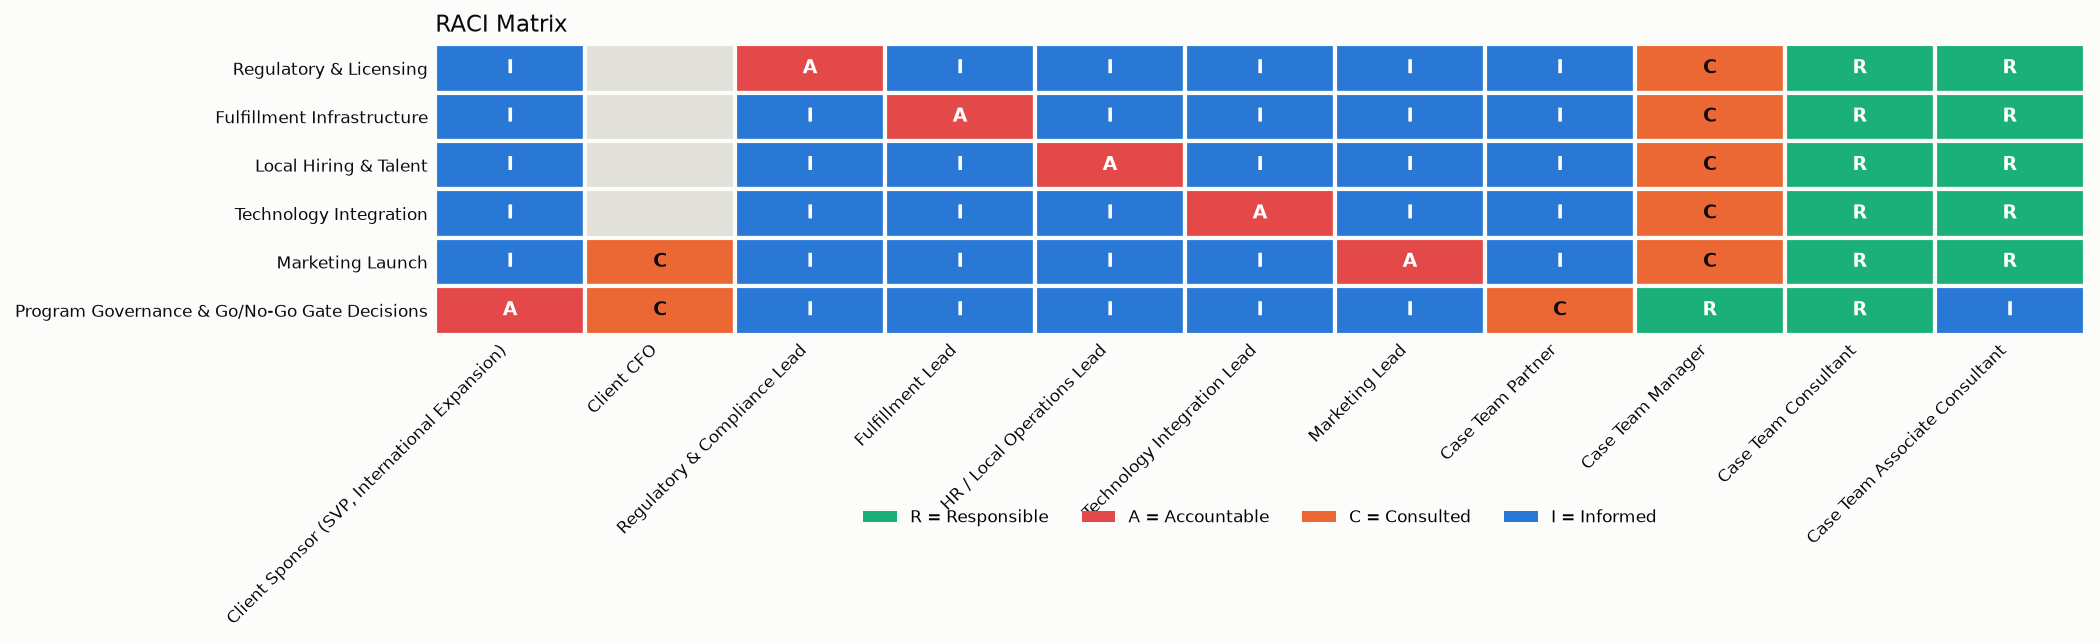

In [4]:
from strategy_roadmap.raci_builder import build_case_raci, to_markdown as raci_to_markdown
from strategy_roadmap._viz import plot_raci_heatmap

raci_matrix = build_case_raci(workstreams)
print(raci_to_markdown(raci_matrix))

fig = plot_raci_heatmap(raci_matrix)
fig.savefig(EXHIBITS / "raci_heatmap.png")
plt.show()


## 4. Milestone timeline with go/no-go gates

Phase 0 diligence → Phase 1 pilot launch → Phase 2 go/no-go gate → Phase 3
scale-up. The gate at the end of Phase 1 is where this project connects
back most directly to the original case: every criterion tied to a
hypothesis id below is a **falsifiable test of exactly the branch the
original analysis couldn't close** without in-market data.

## Milestone Timeline

| Phase | Weeks | Duration | Active Workstreams |
|---|---|---|---|
| Phase 0: Diligence & Mobilization | 1-16 | 16w | WS1, WS2, WS3, WS4 |
| Phase 1: Pilot Launch & Live Operation | 17-94 | 78w | WS2, WS3, WS4, WS5 |
| Phase 2: Go/No-Go Gate | 95-98 | 4w | - |
| Phase 3: Scale-Up Mobilization | 99-130 | 32w | WS1, WS2, WS3, WS4, WS5 |

### Phase 0: Diligence & Mobilization (weeks 1-16)
**Objectives:**
- Secure regulatory clearance to operate in Ontario
- Sign partner-store and courier agreements for the pilot zone
- Hire and onboard the pilot-zone operations team
- Localize the ordering/payments platform for the Canadian market

**Pilot Readiness Gate** (week 16, decision owner: MANAGER)

| Criterion | Tied to hypothesis |
|---|---|
| Ontario business license and GST/HST registration obtained | - |
| Partner-store picking agreements signed for the pilot zone | - |
| Last-mile courier network contracted with agreed SLAs | - |
| Pilot-zone operations team hired an

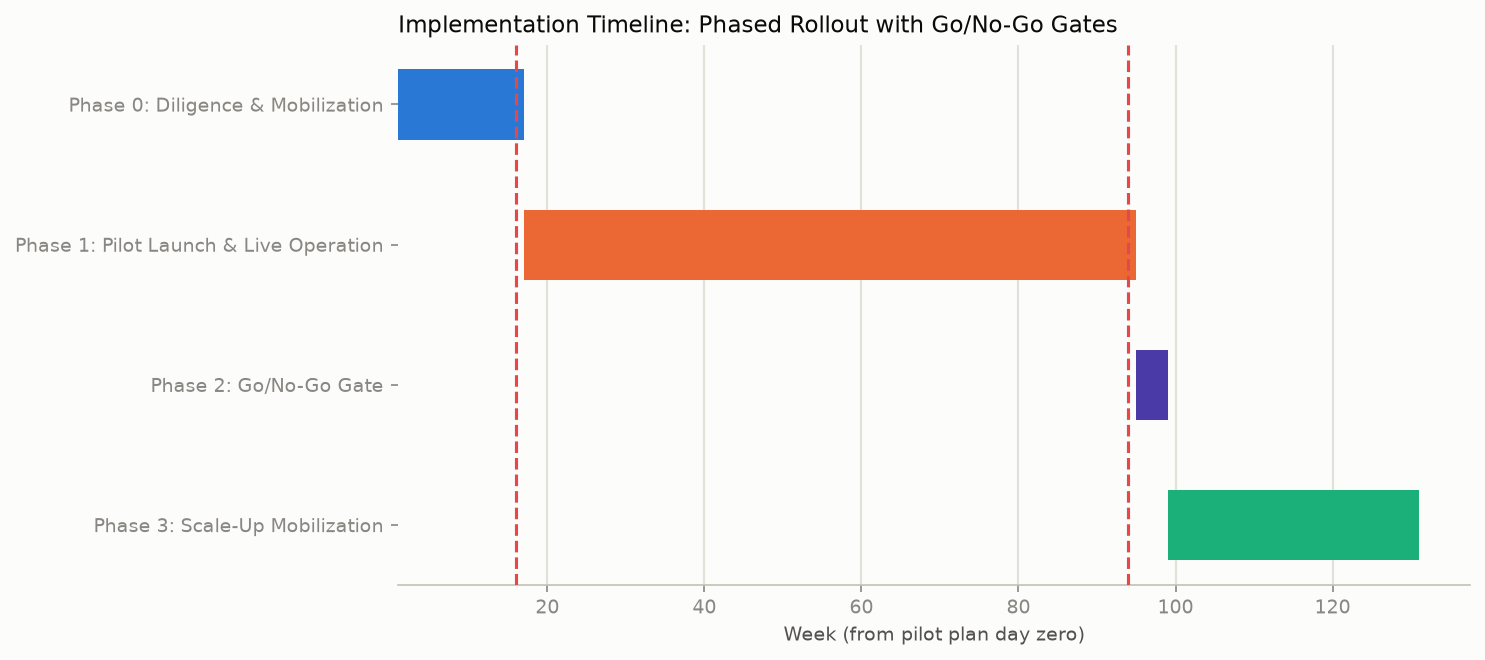

In [5]:
from strategy_roadmap.milestone_timeline import build_timeline, gates, to_markdown as timeline_to_markdown
from strategy_roadmap._viz import plot_gantt_timeline

phases = build_timeline()
print(timeline_to_markdown(phases))

fig = plot_gantt_timeline(phases)
fig.savefig(EXHIBITS / "gantt_timeline.png")
plt.show()


## 5. Implementation risk register

This is a *different* risk register from anything the original case toolkit
produced — that project assessed whether the market was worth entering
(sizing, competition, financial feasibility); this one assesses the risk of
**executing** the pilot. Several rows are written as the operational failure
mode of the same unresolved hypotheses from Section 1: an early-warning
indicator here is what would tell the team a gate criterion is heading for a
"no" well before the gate itself convenes.

## Implementation Risk Register

| ID | Category | Risk | Likelihood | Impact | Score | Severity | Mitigation Owner | Early-Warning Indicator |
|---|---|---|---|---|---|---|---|---|
| R7 | Marketing / Commercial | Customer acquisition cost (CAC) exceeds the financial model's threshold because the pilot-zone campaign attracts low-intent or out-of-zone customers | 3 | 5 | 15 | High | MKT_LEAD | Blended CAC exceeds the financial model's threshold for 2+ consecutive reporting weeks |
| R8 | Marketing / Commercial | Pilot-zone customer retention falls short of the level the financial model requires, driven by delivery reliability or assortment gaps rather than price | 3 | 5 | 15 | High | MKT_LEAD | Week-8 cohort retention trending below the financial model's required curve |
| R1 | Fulfillment | Partner-store picking accuracy or throughput degrades once real pilot-zone order volume hits, beyond what was tested in the initial agreement | 3 | 4 | 12 | High | FULFILL_LEAD | Picking-error rate 

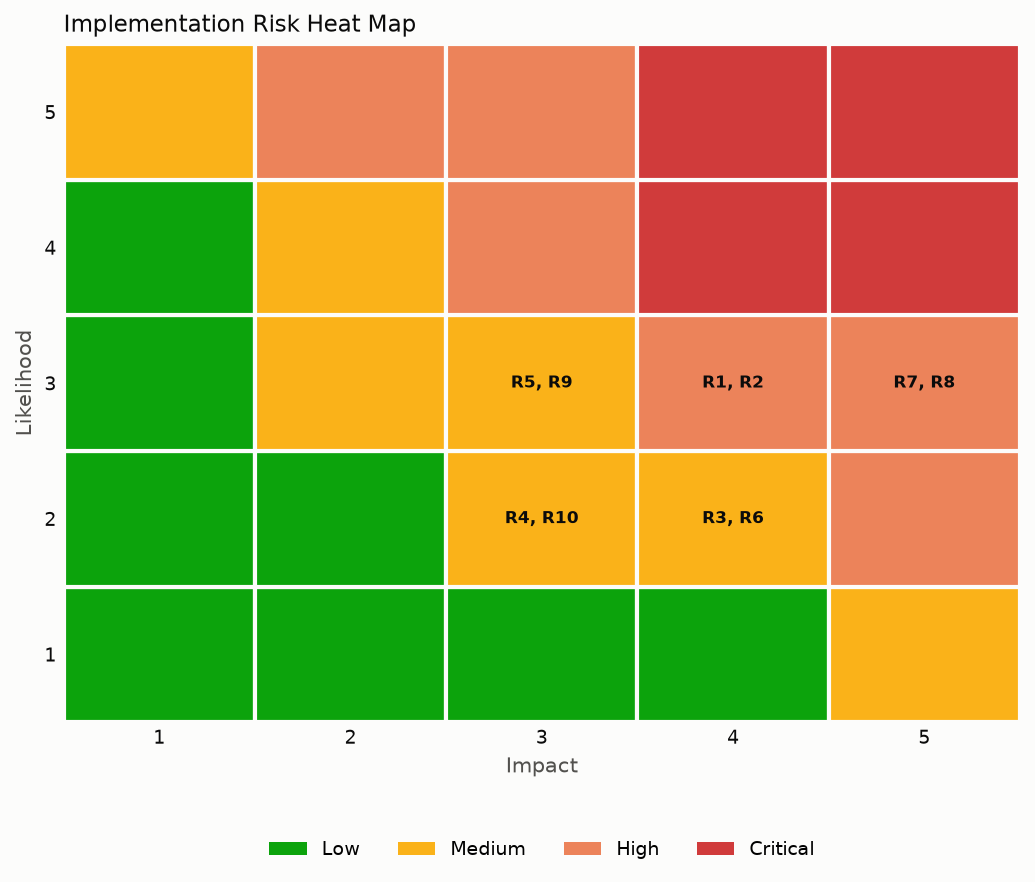

In [6]:
from strategy_roadmap.risk_register import build_risk_register, to_markdown as risk_to_markdown
from strategy_roadmap._viz import plot_risk_heatmap

risks = build_risk_register()
print(risk_to_markdown(risks))

fig = plot_risk_heatmap(risks)
fig.savefig(EXHIBITS / "risk_heatmap.png")
plt.show()


## 6. Stakeholder communications & change management

The "soft skills" layer, made concrete and structured rather than left as
prose: who gets told what, how often, through what channel — plus a written
narrative on the specific organizational friction this pilot will create
(new hires joining mid-implementation, decision-rights ambiguity between the
existing U.S. operations team and the new GTA pilot team) and how the case
team plans to manage it.

The narrative below is generated by `synthesize_change_narrative()`, which
mirrors the sibling toolkit's `memo_synthesis.py` pattern: a fully offline,
deterministic **template mode** (what actually produced this notebook's
output — no API key was available in the environment this was built in),
and an optional **live mode** that calls the Anthropic API if
`ANTHROPIC_API_KEY` is set. Either way, a human case-team reviewer is
expected to work through `REVIEW_CHECKLIST` before this goes anywhere near
client leadership.

In [7]:
from strategy_roadmap.stakeholder_comms import (
    build_change_management_inputs,
    build_communication_plan,
    print_review_checklist,
    synthesize_change_narrative,
    to_markdown as comms_to_markdown,
)

comms_plan = build_communication_plan()
print(comms_to_markdown(comms_plan))

change_inputs = build_change_management_inputs(case, workstreams, risks)
narrative, mode = synthesize_change_narrative(change_inputs)
print(f"(synthesized in '{mode}' mode)\n")
print(narrative)
print()
print_review_checklist()


## Stakeholder Communication Plan

| Audience | Frequency | Channel | Content Focus | Owner |
|---|---|---|---|---|
| Client Sponsor & CFO (Steering Committee) | Monthly | Steering committee readout (deck + live discussion) | Progress against gate criteria, financial tracking, top risks, decisions needed from leadership | PARTNER |
| Client Functional Leads (Regulatory, Fulfillment, HR, Technology, Marketing) | Weekly | Cross-functional operations sync (video call) | Workstream status, blockers, and dependency handoffs between workstreams | MANAGER |
| Pilot-Zone Operations Team (including new hires) | Daily | Stand-up (in-person or video) | Day-to-day execution status, immediate blockers, onboarding support for new team members | HR_LEAD |
| Broader Client Organization (existing US operations and other functions) | Monthly | Company newsletter / all-hands update | Pilot milestones reached, what to expect next, how the pilot affects existing teams' processes or shared systems | MANAGER

## 7. Team staffing & mentorship plan

The piece most directly aimed at the Consultant-vs-Associate-Consultant
distinction: not just *what* work needs doing, but how a case team staffs
against it across seniority levels, and specifically how a junior team
member gets brought up to speed when they join **mid-implementation** rather
than at a clean project kickoff — a direct, structured answer to "mentor
junior team members," not a bullet point about it.

In [8]:
from strategy_roadmap.staffing_plan import (
    build_mentorship_plan,
    build_staffing_plan,
    to_markdown as staffing_to_markdown,
)

staffing = build_staffing_plan()
mentorship = build_mentorship_plan()
print(staffing_to_markdown(staffing, mentorship))


## Team Staffing & Mentorship Plan

### Staffing Allocation

| Seniority | % of Time on Engagement | WS1 | WS2 | WS3 | WS4 | WS5 | GOV | MENTORSHIP |
|---|---|---|---|---|---|---|---|---|
| Partner | 10% | 5% | 5% | 0% | 0% | 10% | 70% | 10% |
| Manager | 75% | 15% | 20% | 15% | 15% | 15% | 10% | 10% |
| Consultant | 100% | 15% | 25% | 15% | 20% | 15% | 5% | 5% |
| Associate Consultant | 100% | 10% | 20% | 20% | 20% | 20% | 5% | 5% |

*Percentages in WS1-WS5/GOV/MENTORSHIP columns are each person's own time split, not a share of the whole team's effort.*

### Onboarding & Mentorship Plan (Associate Consultant joining mid-implementation)

**Week 0: Context handoff session** (mentor: Manager)
- Full walkthrough of the case history: the original hypothesis tree and conditional-go recommendation (case_context.py), current workstream status (workstream_planner.py), the RACI matrix, and the live risk register -- delivered by the Manager and Consultant together, using this package's own outpu

## 8. Assembling the final roadmap document

`roadmap_synthesis.py` runs every module above (independently of this
notebook's already-computed variables, so it's a true end-to-end
regeneration) and combines them into the single document a case team would
actually leave with a client: `outputs/implementation_roadmap.md`, with the
three exhibits embedded.

Wrote /home/user/strategy-implementation-roadmap/outputs/implementation_roadmap.md
Exhibits in /home/user/strategy-implementation-roadmap/outputs/exhibits: ['gantt_timeline.png', 'raci_heatmap.png', 'risk_heatmap.png']


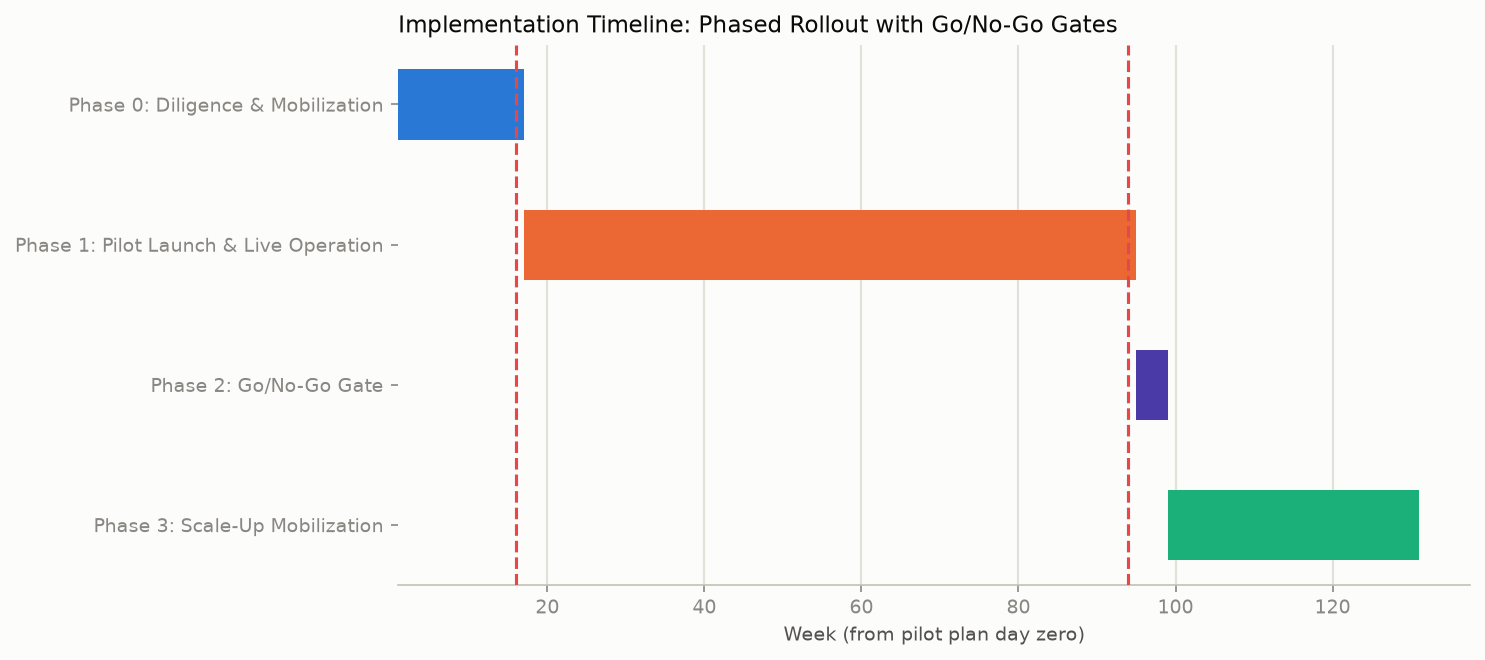

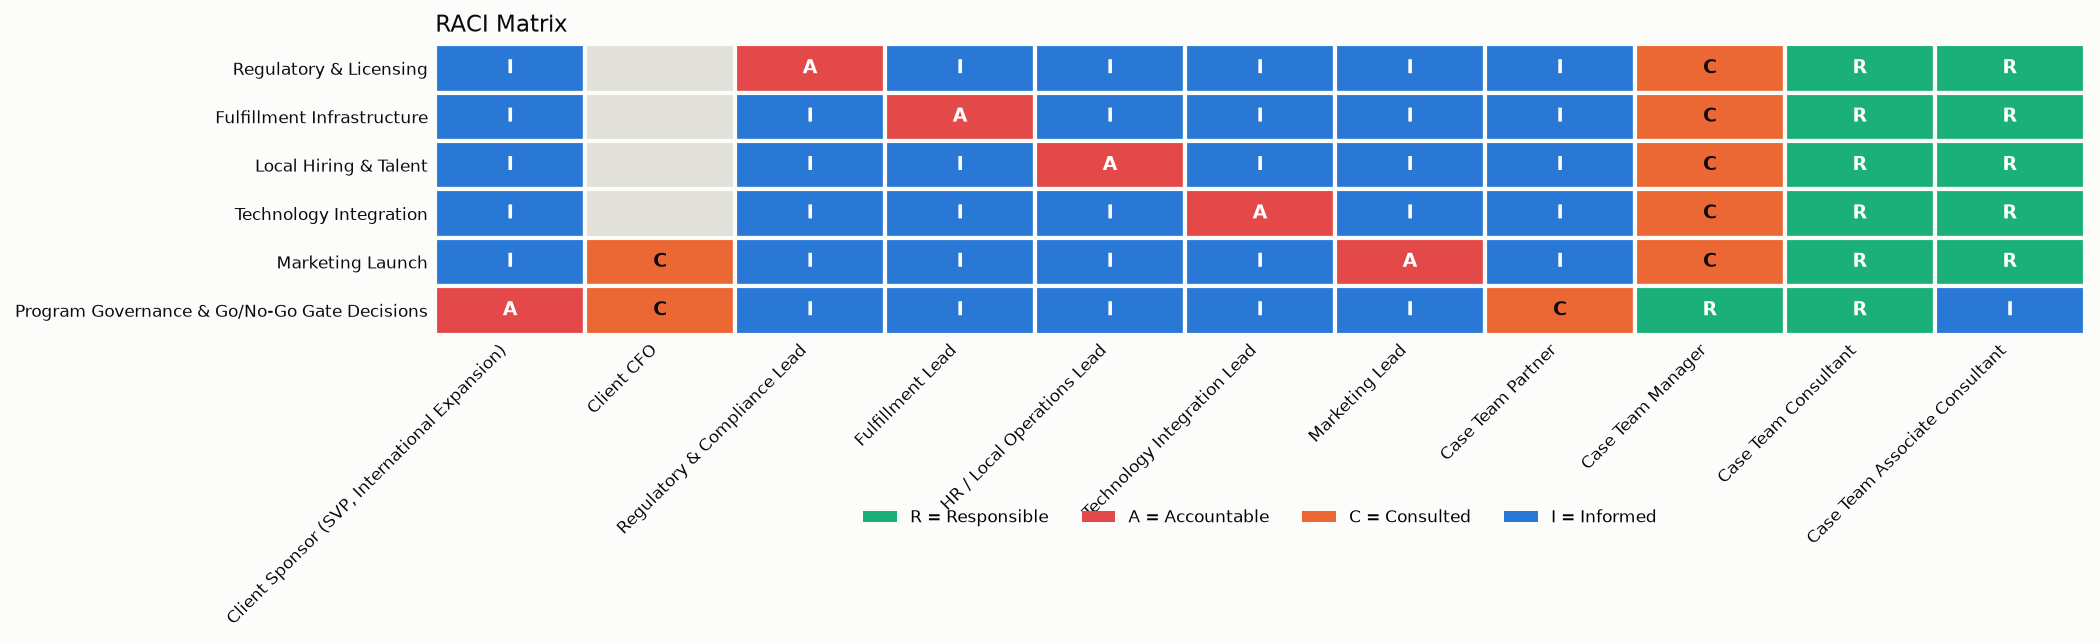

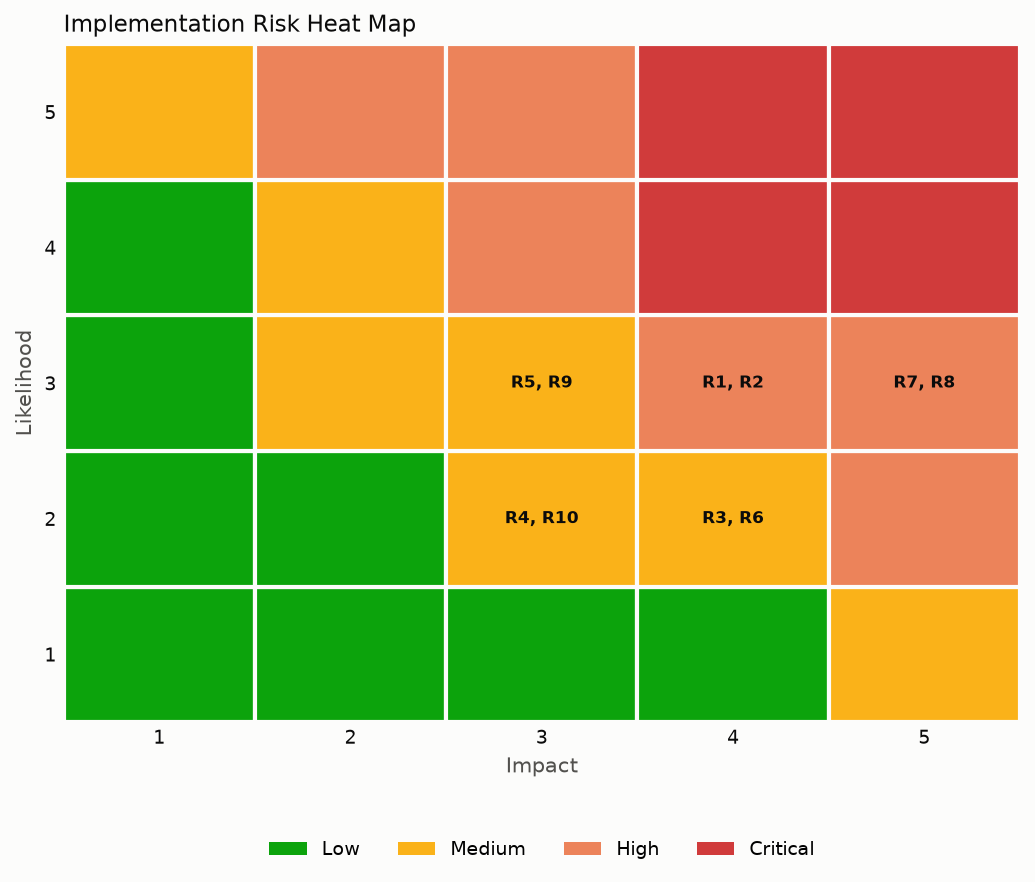

In [9]:
from strategy_roadmap.roadmap_synthesis import generate_roadmap

doc_path = generate_roadmap(OUTPUTS, use_live_llm=False)
print(f"Wrote {doc_path}")
print(f"Exhibits in {EXHIBITS}: {sorted(p.name for p in EXHIBITS.glob('*.png'))}")


## Where this leaves things

Together, `market-entry-case-toolkit` and `strategy-implementation-roadmap`
work one case end to end the way a real engagement would: frame the
question as a hypothesis tree, run the analysis, reach a — sometimes
conditional — recommendation, and then build the plan that actually gets it
done: who owns what, when the client can still walk away cheaply, what
could go wrong operationally, how the organization gets managed through the
change, and how the team staffs and mentors its way through execution.

**Disclaimer:** FreshRoute is a fictional company built for this exercise.
Every workstream, stakeholder, timeline, risk score, and staffing
allocation in this project is an illustrative, hand-set proxy for a
portfolio case study — not real client data, and not an actual
implementation plan for any named company. See the README for the full
disclaimer.